# Занятие 4. Проектирование инновационных систем, edge и роботы

**Цель занятия:** превратить идею в проверяемое ТЗ, понять цену запуска модели на устройстве
и собрать все слои курса в одну систему.

- Методология: JTBD → требования → архитектура (C4-lite)
- Edge: ONNX, квантизация, бюджет latency/памяти/энергии
- Робототехника: сенсоры → восприятие → планирование → управление
- Инновационность: матрица «новизна × ценность»
- Разбор тем проектов
- Шаблон ТЗ и короткого питча

**Про железо.** GPU не требуется: экспорт в ONNX, квантование и замеры идут на CPU.

In [ ]:
import os, sys, json, time, warnings, subprocess
from dataclasses import dataclass, field, asdict
from typing import Dict, List, Optional, Tuple, Type

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
try:
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()
except Exception:
    pass

IN_COLAB = "COLAB_GPU_TOPOLOGY" in os.environ or os.path.exists("/content")
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "onnx", "onnxruntime", "optimum", "transformers", "torch"])

ART = "/home/user/course/artifacts"
os.makedirs(ART, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
print(f"Устройство: {DEVICE} | torch {torch.__version__}")

Устройство: cpu | torch 2.14.1+cpu


## Зачем это и где применяется

**Зачем.** Две типичные причины провала проекта: требование без числа («работает быстро») — такое
нельзя принять, и модель, которая не влезает в устройство по памяти или latency. Первое лечится
ТЗ с измеримыми критериями, второе — переводом модели в ONNX/int8 и честным замером до и после.

**Где применяется.** Встраиваемые системы и роботы (Jetson, Raspberry Pi, NPU в смартфоне),
мобильные приложения, промышленные контроллеры — везде, где есть жёсткий бюджет по памяти,
времени отклика и энергии.

Это слой развёртывания: он берёт восприятие, мозг и агента и превращает их
в изделие, которое можно показать и измерить.

## Термины занятия (глоссарий)

| Термин | Смысл |
|---|---|
| **JTBD** | Jobs To Be Done: формулировка через «какую работу пользователь нанимает продукт выполнить» |
| **Функциональное требование** | что система делает |
| **Нефункциональное требование** | как она это делает: latency, память, энергия, надёжность |
| **C4-lite** | упрощённая схема архитектуры: контекст → контейнеры → компоненты |
| **ONNX** | открытый формат графа модели: одна модель — разные рантаймы и железо |
| **Квантование (int8)** | веса в 1 байт вместо 4: −75% памяти, возможна потеря качества |
| **Дистилляция** | маленькая модель-ученик повторяет логиты большой модели-учителя |
| **NPU / Edge TPU** | ускоритель на устройстве: быстрее и энергоэффективнее CPU, но не все операции поддерживаются |
| **RSS** | Resident Set Size — фактически занятая процессом оперативная память |
| **p95 latency** | время, хуже которого только 5% запросов |
| **Привод (actuator)** | исполнительное устройство — мотор, реле: превращает решение в действие |


### Архитектура занятия и выбор инструментов

```
идея ──JTBD──▶ требования ──▶ архитектура ──▶ метрики ──▶ приёмка ──▶ демонстрация
                                    │
        восприятие (ДЗ-1) ── мозг (ДЗ-2) ── оркестрация (ДЗ-3) ── edge (это занятие)
```

| Решение | Пояснение |
|---|---|
| ONNX + ONNX Runtime | один файл модели запускается на CPU, GPU и ускорителях без переписывания кода; ORT делает граф-оптимизации сам |
| Динамическое квантование | веса в int8, активации квантуются на ходу: калибровочная выборка не нужна — важно для занятия |
| Оценка FLOPs вручную | оценка грубая (без учёта пропускной способности памяти), но отсекает заведомо невыполнимые конфигурации |
| Функции-шаги вместо иерархии классов | восприятие, планировщик и приводы подменяются заглушкой — пайплайн проверяется без «железа» |
| Демо-ТЗ с провалами | приёмка показывает «2 из 6», а не «работает хорошо»: требование без числа нельзя принять |


## 1. Методология: от идеи к проверяемому ТЗ

**Цепочка:** Jobs-to-be-done → пользователь и сценарий → функциональные/нефункциональные требования →
архитектура (C4-lite) → критерии приёмки с числами.

In [ ]:
from enum import Enum

class RequirementType(str, Enum):
    functional = "функциональное"
    performance = "производительность"
    resource = "ресурс"
    quality = "качество"
    safety = "безопасность"

@dataclass
class Requirement:
    """Проверяемое требование: метрика + целевое значение + условие + метод измерения."""
    id: str
    type: RequirementType
    text: str
    metric: str
    target: float
    comparator: str = ">="            # ">=", "<=", "=="
    how_to_measure: str = ""

    def check(self, value: Optional[float]) -> Tuple[bool, str]:
        if value is None:
            return False, f"{self.id}: значение не измерено"
        ok = {">=": value >= self.target, "<=": value <= self.target,
              "==": abs(value - self.target) < 1e-9}[self.comparator]
        return ok, f"{self.id} [{self.metric}]: {value} {self.comparator} {self.target} -> {'OK' if ok else 'ПРОВАЛ'}"

@dataclass
class Spec:
    """Техническое задание (C4-lite: контекст + контейнеры + ключевые компоненты)."""
    problem: str
    user: str
    scenario: str
    requirements: List[Requirement] = field(default_factory=list)
    architecture: Dict[str, List[str]] = field(default_factory=dict)
    risks: List[str] = field(default_factory=list)

    def acceptance_report(self, measurements: Dict[str, float]) -> pd.DataFrame:
        rows = []
        for req in self.requirements:
            ok, msg = req.check(measurements.get(req.metric))
            rows.append(dict(id=req.id, тип=req.type.value, требование=req.text[:60],
                             метрика=req.metric, измерено=measurements.get(req.metric),
                             цель=f"{req.comparator} {req.target}", статус="OK" if ok else "ПРОВАЛ"))
        return pd.DataFrame(rows)

demo_spec = Spec(
    problem="Оператор тратит 40% смены на обход склада и поиск повреждённой упаковки.",
    user="Оператор склада (2 человека в смену), базовые навыки работы с планшетом.",
    scenario="Ровер объезжает стеллажи, снимает видео, детектит повреждения, голосом принимает команды "
             "оператора и выдаёт отчёт со списком проблемных мест.",
    requirements=[
        Requirement("FR-1", RequirementType.functional, "Система распознаёт повреждения упаковки",
                    "precision", 0.85, ">=", "на отложенной выборке ≥200 кадров"),
        Requirement("FR-2", RequirementType.functional, "Система распознаёт голосовые команды оператора",
                    "wer", 0.20, "<=", "20 фраз, jiwer"),
        Requirement("NFR-1", RequirementType.performance, "Решение выдаётся не дольше чем через 300 мс",
                    "latency_ms", 300.0, "<=", "замер на целевом устройстве, p95"),
        Requirement("NFR-2", RequirementType.resource, "Потребление памяти модели ≤ 500 МБ",
                    "memory_mb", 500.0, "<=", "RSS процесса на устройстве"),
        Requirement("NFR-3", RequirementType.quality, "Доля ложных тревог не выше 10%",
                    "false_alarm_rate", 0.10, "<=", "на прогоне по складу"),
        Requirement("S-1", RequirementType.safety, "Команда «стоп» останавливает платформу ≤ 200 мс",
                    "stop_latency_ms", 200.0, "<=", "аппаратный тест"),
    ],
    architecture={"Восприятие": ["ViT (детекция повреждений)", "Whisper (команды)"],
                  "Мозг": ["LLM + LoRA/DPO", "квантование int8"],
                  "Оркестрация": ["LangGraph-агент", "MCP-инструменты", "A2A для агентов зон"],
                  "Железо": ["Jetson Orin Nano", "камера", "микрофон", "приводы"]},
    risks=["Нехватка размеченных данных по редким типам повреждений",
           "Шум на складе снижает качество ASR",
           "Разряд батареи при непрерывном обходе > 2 ч"],
)
print(demo_spec.problem)
print("Требований:", len(demo_spec.requirements))

Оператор тратит 40% смены на обход склада и поиск повреждённой упаковки.
Требований: 6


### 1.1 Приёмка: требования против измерений

Пока значений нет — все требования «ПРОВАЛ». Это правильное поведение: ТЗ обязано «болеть»,
пока вы не принесли числа.

In [ ]:
measurements_demo = {"precision": 0.81, "wer": 0.24, "latency_ms": 410.0,
                     "memory_mb": 380.0, "false_alarm_rate": 0.07}
report = demo_spec.acceptance_report(measurements_demo)
display(report)
print("Принято:", int((report["статус"] == "OK").sum()), "из", len(report))
print("Вывод: проект не принят — не добрали precision и WER, latency выше бюджета.")
print("Именно так выглядит честный отчёт: не «работает хорошо», а «3 из 6 критериев не выполнены».")

,id,тип,требование,метрика,измерено,цель,статус
0,FR-1,функциональное,Система распознаёт повреждения упаковки,precision,0.81,>= 0.85,ПРОВАЛ
1,FR-2,функциональное,Система распознаёт голосовые команды оператора,wer,0.24,<= 0.2,ПРОВАЛ
2,NFR-1,производительность,Решение выдаётся не дольше чем через 300 мс,latency_ms,410.00,<= 300.0,ПРОВАЛ
3,NFR-2,ресурс,Потребление памяти модели ≤ 500 МБ,memory_mb,380.00,<= 500.0,OK
4,NFR-3,качество,Доля ложных тревог не выше 10%,false_alarm_rate,0.07,<= 0.1,OK
5,S-1,безопасность,Команда «стоп» останавливает платформу ≤ 200 мс,stop_latency_ms,NaN,<= 200.0,ПРОВАЛ


Принято: 2 из 6
Вывод: проект не принят — не добрали precision и WER, latency выше бюджета.
Именно так выглядит честный отчёт: не «работает хорошо», а «3 из 6 критериев не выполнены».


## 2. Edge-развёртывание: ONNX и квантизация

Путь модели на устройство: **PyTorch → ONNX → (опционально) квантизация → рантайм (ONNX Runtime / TensorRT / TFLite)**.
Обязательно замеряем три величины: размер, latency, деградацию качества.

In [ ]:
!pip install onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 16.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [onnxscript]


In [ ]:
from transformers import ViTForImageClassification, ViTConfig

def onnx_size_kb(path: str) -> float:
    """Размер ONNX-модели с учётом внешнего файла весов (.onnx.data).
   экспортёр выносит большие тензоры в отдельный файл — без этого размер сильно занижается."""
    total = os.path.getsize(path)
    ext = path + ".data"
    if os.path.exists(ext):
        total += os.path.getsize(ext)
    return total / 1024

def build_small_vit(num_labels: int = 4, size: int = 32) -> ViTForImageClassification:
    cfg = ViTConfig(hidden_size=96, num_hidden_layers=3, num_attention_heads=3, intermediate_size=192,
                    image_size=size, patch_size=8, num_labels=num_labels, num_channels=3)
    return ViTForImageClassification(cfg)

model = build_small_vit().eval()
dummy = torch.randn(1, 3, 32, 32)
with torch.no_grad():
    ref_out = model(pixel_values=dummy).logits.numpy()

onnx_fp32 = f"{ART}/vit_fp32.onnx"
onnx_int8 = f"{ART}/vit_int8.onnx"

# экспорт с динамической осью batch: один файл работает с любым размером батча
with torch.no_grad():
    torch.onnx.export(model, (dummy,), onnx_fp32, input_names=["pixel_values"],
                      output_names=["logits"], dynamic_axes={"pixel_values": {0: "batch"}},
                      opset_version=18)
print("ONNX экспортирован:", onnx_fp32,
      f"({onnx_size_kb(onnx_fp32):.0f} КБ)")

import onnxruntime as ort
# рантайм читает тот же файл: сравниваем логиты ORT с логитами PyTorch, чтобы убедиться в экспорте
sess_fp32 = ort.InferenceSession(onnx_fp32, providers=["CPUExecutionProvider"])
out_fp32 = sess_fp32.run(None, {"pixel_values": dummy.numpy()})[0]
print("Макс. расхождение PyTorch vs ONNX:", float(np.abs(out_fp32 - ref_out).max()))

[torch.onnx] Obtain model graph for `ViTForImageClassification([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ViTForImageClassification([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX экспортирован: /home/user/course/artifacts/vit_fp32.onnx (1222 КБ)
Макс. расхождение PyTorch vs ONNX: 1.043081283569336e-07


### 2.1 Квантизация ONNX-модели и замер latency

In [ ]:
from onnxruntime.quantization import quantize_dynamic, QuantType

# динамическое квантование: веса в int8, активации квантуются на ходу во время исполнения
quantize_dynamic(onnx_fp32, onnx_int8, weight_type=QuantType.QInt8)
sess_int8 = ort.InferenceSession(onnx_int8, providers=["CPUExecutionProvider"])
out_int8 = sess_int8.run(None, {"pixel_values": dummy.numpy()})[0]

# замер: сначала прогрев, потом усреднение по N прогонов — одиночный запуск на CPU сильно шумит
def bench_ort(sess, input_name="pixel_values", n=100, batch=1) -> float:
    x = np.random.randn(batch, 3, 32, 32).astype(np.float32)
    for _ in range(10):                       # прогрев
        sess.run(None, {input_name: x})
    t0 = time.time()
    for _ in range(n):
        sess.run(None, {input_name: x})
    return (time.time() - t0) / n * 1000      # мс

rows = []
for name, sess, path in [("fp32", sess_fp32, onnx_fp32), ("int8", sess_int8, onnx_int8)]:
    lat = bench_ort(sess)
    rows.append(dict(вариант=name, размер_КБ=round(onnx_size_kb(path), 1),
                     latency_мс=round(lat, 2),
                     макс_отклонение=round(float(np.abs(sess.run(None, {'pixel_values': dummy.numpy()})[0] - ref_out).max()), 5)))
df_edge = pd.DataFrame(rows)
display(df_edge)
print("Как считать размер: новый экспортёр ONNX выносит веса в отдельный файл <model>.onnx.data —")
print("если считать только .onnx, размер fp32-модели будет занижен в десятки раз.")
print("Выигрыш по размеру на маленьких моделях скромнее, чем на моделях от сотен миллионов параметров:")
print("у квантования есть накладные расходы (scale/zero-point), а часть весов (embedding) часто остаётся без квантования.")
print("Всегда меряйте на своей модели и своей платформе.")

,вариант,размер_КБ,latency_мс,макс_отклонение
0,fp32,1222.4,4.6,0.00000
1,int8,494.1,7.8,0.00652


Как считать размер: новый экспортёр ONNX выносит веса в отдельный файл <model>.onnx.data —
если считать только .onnx, размер fp32-модели будет занижен в десятки раз.
Выигрыш по размеру на маленьких моделях скромнее, чем на моделях от сотен миллионов параметров:
у квантования есть накладные расходы (scale/zero-point), а часть весов (embedding) часто остаётся без квантования.
Всегда меряйте на своей модели и своей платформе.


## 3. Бюджет устройства: калькулятор

Три вопроса перед выбором железа: **сколько весов влезет**, **уложимся ли в latency**,
**сколько энергии съедим**. Ниже — калькулятор по параметрам модели и ориентиры по платформам.

In [ ]:
@dataclass
class Device:
    name: str
    ram_mb: int
    ops_gflops: float          # грубая оценка пиковой производительности
    power_w: float             # типовое энергопотребление
    notes: str = ""

DEVICES = [
    Device("Raspberry Pi 5 (CPU)", 8192, 15, 6.0, "дешёво, но медленно для трансформеров"),
    Device("Jetson Orin Nano (GPU)", 8192, 500, 12.0, "основной кандидат для ViT/LLM на борту"),
    Device("Coral TPU (Edge TPU)", 1024, 100, 2.5, "только int8, нужна компиляция модели"),
    Device("Смартфон (NPU)", 6144, 300, 3.5, "хорошо для субтитров и лёгких моделей"),
    Device("Серверная GPU (T4)", 16384, 8000, 70.0, "эталон для сравнения: без ограничений"),
]

def estimate(params_m: float, bytes_per_param: float, seq_tokens: int,
             device: Device) -> Dict[str, float]:
    """Грубая оценка: память под веса, время прямого прохода и энергия на запрос."""
    weights_mb = params_m * 1e6 * bytes_per_param / (1024 ** 2)
    activations_mb = weights_mb * 0.25                       # очень грубо: KV-кэш/активации
    total_mb = weights_mb + activations_mb
    # 2 * параметры * токены: на каждый параметр приходятся умножение и сложение
    flops = 2 * params_m * 1e6 * seq_tokens
    latency_ms = flops / (device.ops_gflops * 1e9) * 1000     # время = объём вычислений / производительность
    energy_j = latency_ms / 1000 * device.power_w
    fits = total_mb <= device.ram_mb * 0.7                   # оставляем 30% системе
    return dict(память_МБ=round(total_mb, 1), latency_мс=round(latency_ms, 1),
                энергия_Дж=round(energy_j, 2), влезает=bool(fits))

rows = []
for model_name, params_m, bpp in [("ViT-base (fp32)", 86, 4), ("ViT-base (int8)", 86, 1),
                                  ("Whisper-small (fp32)", 244, 4), ("Whisper-small (int8)", 244, 1),
                                  ("LLM 0.5B (fp16)", 500, 2), ("LLM 0.5B (int4)", 500, 0.5)]:
    for dev in DEVICES:
        est = estimate(params_m, bpp, seq_tokens=64, device=dev)
        rows.append(dict(модель=model_name, платформа=dev.name, **est))
df_budget = pd.DataFrame(rows)
display(df_budget.pivot(index="модель", columns="платформа", values="latency_мс").round(1))
display(pd.DataFrame([asdict(d) for d in DEVICES])[["name", "ram_mb", "ops_gflops", "power_w", "notes"]])
print("Как пользоваться: сначала проверяйте «влезает ли по памяти», потом — latency, затем энергию.")
print("Оценка грубая (без учёта пропускной способности памяти), но она ловит главное —")
print("попытки засунуть 0.5B-модель на Raspberry Pi без квантования.")

платформа,Coral TPU (Edge TPU),Jetson Orin Nano (GPU),Raspberry Pi 5 (CPU),Серверная GPU (T4),Смартфон (NPU)
модель,,,,,
LLM 0.5B (fp16),640.0,128.0,4266.7,8.0,213.3
LLM 0.5B (int4),640.0,128.0,4266.7,8.0,213.3
ViT-base (fp32),110.1,22.0,733.9,1.4,36.7
ViT-base (int8),110.1,22.0,733.9,1.4,36.7
Whisper-small (fp32),312.3,62.5,2082.1,3.9,104.1
Whisper-small (int8),312.3,62.5,2082.1,3.9,104.1


,name,ram_mb,ops_gflops,power_w,notes
0,Raspberry Pi 5 (CPU),8192,15,6.0,"дешёво, но медленно для трансформеров"
1,Jetson Orin Nano (GPU),8192,500,12.0,основной кандидат для ViT/LLM на борту
2,Coral TPU (Edge TPU),1024,100,2.5,"только int8, нужна компиляция модели"
3,Смартфон (NPU),6144,300,3.5,хорошо для субтитров и лёгких моделей
4,Серверная GPU (T4),16384,8000,70.0,эталон для сравнения: без ограничений


Как пользоваться: сначала проверяйте «влезает ли по памяти», потом — latency, затем энергию.
Оценка грубая (без учёта пропускной способности памяти), но она ловит главное —
попытки засунуть 0.5B-модель на Raspberry Pi без квантования.


## 4. Робототехнический пайплайн

```
камера ──▶ ViT (восприятие) ──┐
микрофон ─▶ Whisper ──────────┼──▶ Планировщик (LLM/агент) ──▶ MCP-инструменты ──▶ приводы
лидар ───▶ препятствия ───────┘            ▲                                          │
                                           └──────────────── обратная связь ◀──────────┘
```

Каждый шаг — отдельная функция с понятной сигнатурой: `observe` (восприятие), `plan` (решение),
`act` (приводы). Такой «функциональный» стык проще, чем иерархия классов: любой шаг можно подменить
заглушкой в тесте, не трогая остальные. Наследование здесь ничего не даёт — общее у шагов только то,
что они принимают и возвращают словарь.

In [ ]:
COMMAND_ACTIONS = {"stop": "остановиться", "forward": "двигаться вперёд", "back": "назад",
                   "left": "влево", "right": "вправо", "home": "на базу"}
LATENCY_BUDGET_MS = 300.0

def observe(frame: Dict, latency_ms: float = 20.0) -> Dict:
    """Восприятие: заглушка вместо ViT + Whisper (задержка имитирует инференс моделей)."""
    time.sleep(latency_ms / 1000)
    return {"object": frame.get("object", "box"), "confidence": frame.get("confidence", 0.9),
            "command": frame.get("command", "forward")}

def plan(observation: Dict, min_confidence: float = 0.6) -> Dict:
    """Планировщик: правила вместо LLM-агента. Учитывает порог уверенности восприятия."""
    if observation["confidence"] < min_confidence:
        return {"action": "ask_operator", "reason": "низкая уверенность восприятия", "safe": True}
    if observation["command"] == "stop":
        return {"action": "stop", "reason": "команда оператора", "safe": True}
    return {"action": COMMAND_ACTIONS.get(observation["command"], "stop"),
            "reason": f"объект {observation['object']}", "safe": True}

def act(decision: Dict, latency_ms: float = 10.0) -> Dict:
    """Приводы: имитация исполнения команды с задержкой."""
    time.sleep(latency_ms / 1000)
    return {"status": "done", "action": decision["action"]}

def step(frame: Dict, budget_ms: float = LATENCY_BUDGET_MS) -> Dict:
    """Один шаг пайплайна: наблюдение -> решение -> действие. Порядок вызовов только здесь."""
    # замеряем весь цикл целиком: восприятие + планирование + привод, а не отдельную модель
    t0 = time.time()
    observation = observe(frame)
    decision = plan(observation)
    result = act(decision)
    total_ms = (time.time() - t0) * 1000
    return dict(action=result["action"], reason=decision.get("reason", ""),
                total_ms=round(total_ms, 1), within_budget=total_ms <= budget_ms,
                safe=decision.get("safe", False))

frames = [{"object": "box", "confidence": 0.92, "command": "forward"},
          {"object": "pallet", "confidence": 0.45, "command": "forward"},   # низкая уверенность
          {"object": "box", "confidence": 0.88, "command": "stop"},
          {"object": "box", "confidence": 0.95, "command": "left"}]
# прогоняем четыре кадра: два штатных, один с низкой уверенностью восприятия и один с командой «стоп»
log = [step(f) for f in frames]
for record in log:
    print(record)

lat = [r["total_ms"] for r in log]
print(f"\nСредняя latency шага: {np.mean(lat):.1f} мс | p95: {np.percentile(lat, 95):.1f} мс | "
      f"в бюджете 300 мс: {sum(r['within_budget'] for r in log)}/{len(log)} шагов")
print("Выполненные команды:", [r["action"] for r in log])

{'action': 'двигаться вперёд', 'reason': 'объект box', 'total_ms': 32.6, 'within_budget': True, 'safe': True}
{'action': 'ask_operator', 'reason': 'низкая уверенность восприятия', 'total_ms': 34.4, 'within_budget': True, 'safe': True}
{'action': 'stop', 'reason': 'команда оператора', 'total_ms': 30.5, 'within_budget': True, 'safe': True}
{'action': 'влево', 'reason': 'объект box', 'total_ms': 30.4, 'within_budget': True, 'safe': True}

Средняя latency шага: 32.0 мс | p95: 34.1 мс | в бюджете 300 мс: 4/4 шагов
Выполненные команды: ['двигаться вперёд', 'ask_operator', 'stop', 'влево']


## 5. Матрица инновационности

Как отличить инновацию от интеграции: **новизна** × **ценность** × **реализуемость**.
«Ещё один чат-бот на LLM» проваливается по новизне; «робот-инспектор с обучением на редких дефектах»
имеет новизну в данных и процессе.

,тема,новизна,ценность,реализуемость,индекс,суть
3,Edge-агент промышленной диагностики,3,5,5,3.87,вибрации/снимки + LLM-объяснение + регламенты
0,Автономный инспектор склада,3,5,4,3.10,"ViT-детекция повреждений + голос + MCP-тулы, J..."
2,Робот-репетитор языка,3,4,4,2.77,произношение (Whisper) + мимика (ViT) + план з...
1,Мультимодальный ассистент для слабослышащих,4,5,3,2.68,"жесты + речь + суммаризация, edge — телефон"
5,Помощник хирурга (симуляция),4,4,2,1.60,фазы операции + команды + чек-лист
4,Агентная система мониторинга города,3,4,2,1.39,события + сирены + A2A между районами


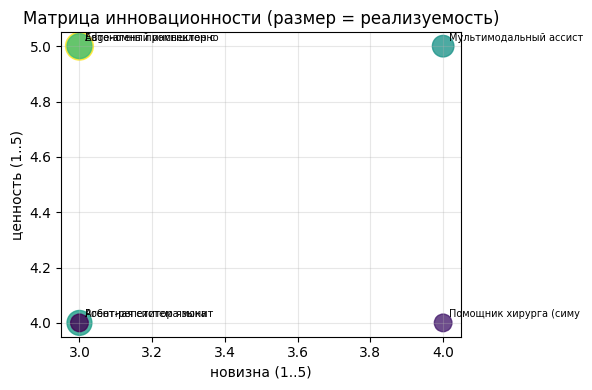

In [ ]:
def innovation_score(novelty: int, value: int, feasibility: int) -> float:
    """Все шкалы 1..5. Реализуемость — множитель: нереализуемая идея не инновация, а фантазия."""
    return round((novelty * value) ** 0.5 * (feasibility / 5), 2)

TOPICS = [
    ("Автономный инспектор склада", 3, 5, 4, "ViT-детекция повреждений + голос + MCP-тулы, Jetson"),
    ("Мультимодальный ассистент для слабослышащих", 4, 5, 3, "жесты + речь + суммаризация, edge — телефон"),
    ("Робот-репетитор языка", 3, 4, 4, "произношение (Whisper) + мимика (ViT) + план занятия"),
    ("Edge-агент промышленной диагностики", 3, 5, 5, "вибрации/снимки + LLM-объяснение + регламенты"),
    ("Агентная система мониторинга города", 3, 4, 2, "события + сирены + A2A между районами"),
    ("Помощник хирурга (симуляция)", 4, 4, 2, "фазы операции + команды + чек-лист"),
]
df_topics = pd.DataFrame([
    dict(тема=t, новизна=n, ценность=v, реализуемость=f,
         индекс=innovation_score(n, v, f), суть=d)
    for t, n, v, f, d in TOPICS]).sort_values("индекс", ascending=False)
display(df_topics)

try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(6, 4))
    plt.scatter(df_topics["новизна"], df_topics["ценность"],
                s=df_topics["реализуемость"] * 80, c=df_topics["индекс"], cmap="viridis", alpha=0.8)
    for _, r in df_topics.iterrows():
        plt.annotate(r["тема"][:22], (r["новизна"], r["ценность"]), fontsize=7,
                     xytext=(4, 4), textcoords="offset points")
    plt.xlabel("новизна (1..5)"); plt.ylabel("ценность (1..5)")
    plt.title("Матрица инновационности (размер = реализуемость)")
    plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
except Exception as e:
    print("график недоступен:", e)

## 6. Шаблон ТЗ и питча

Скопируйте шаблон в свой `hw4_report.md`.

```markdown
## 1. Проблема и пользователь
- JTBD: ...
- Пользователь: ...
- Сценарий «до» и «после»: ...

## 2. Требования
| ID | Тип | Требование | Метрика | Цель | Метод измерения |
|----|-----|-----------|---------|------|-----------------|
| FR-1 | функциональное | ... | precision | ≥ 0.85 | отложенная выборка ≥200 |

## 3. Архитектура (C4-lite)
- Восприятие: ...
- Мозг: ...
- Оркестрация: ...
- Железо: ...

## 4. Метрики и приёмка
| Метрика | Baseline | Наша система | Δ |

## 5. Риски
- ...
```

In [ ]:
def make_spec_template() -> str:
    """Вернуть Markdown-шаблон ТЗ: можно сохранить в файл и заполнить."""
    return """## 1. Проблема и пользователь
- JTBD:
- Пользователь:
- Сценарий «до»:
- Сценарий «после»:

## 2. Требования
| ID | Тип | Требование | Метрика | Цель | Метод измерения |
|----|-----|-----------|---------|------|-----------------|
| FR-1 | функциональное |  |  |  |  |
| NFR-1 | производительность |  | latency_ms | <= 300 | p95 на устройстве |
| NFR-2 | ресурс |  | memory_mb | <= 500 | RSS процесса |

## 3. Архитектура (C4-lite)
- Восприятие (модели, входы/выходы):
- Мозг (LLM, адаптация, компрессия):
- Оркестрация (агент, инструменты, протоколы):
- Железо (платформа, сенсоры, приводы):

## 4. Метрики и приёмка
| Слой | Метрика | Baseline | Наша система |
|------|---------|----------|--------------|

## 5. Риски и план
- Риск 1: ... (митигация: ...)
- План по неделям: ...
"""

template_path = f"{ART}/hw4_spec_template.md"
open(template_path, "w").write(make_spec_template())
print("Шаблон сохранён:", template_path)
print(make_spec_template()[:300] + "...")

Шаблон сохранён: /home/user/course/artifacts/hw4_spec_template.md
## 1. Проблема и пользователь
- JTBD:
- Пользователь:
- Сценарий «до»:
- Сценарий «после»:

## 2. Требования
| ID | Тип | Требование | Метрика | Цель | Метод измерения |
|----|-----|-----------|---------|------|-----------------|
| FR-1 | функциональное |  |  |  |  |
| NFR-1 | производительность |  ...


In [ ]:
artifacts = {
    "acceptance_demo": report.to_dict("records"),
    "edge": df_edge.to_dict("records"),
    "robot": {"steps": log, "mean_latency_ms": round(float(np.mean(lat)), 1),
              "p95_latency_ms": round(float(np.percentile(lat, 95)), 1)},
    "topics": df_topics.to_dict("records"),
    "spec_demo": {"problem": demo_spec.problem,
                  "requirements": [asdict(r) for r in demo_spec.requirements]},
}
json.dump(artifacts, open(f"{ART}/hw4_metrics.json", "w"), ensure_ascii=False, indent=1)
print("Сохранено:", f"{ART}/hw4_metrics.json")

Сохранено: /home/user/course/artifacts/hw4_metrics.json


## 7. Упражнения для самостоятельной работы (в ноутбуке)

1. Добавьте в `demo_spec` требование на точность A2A-взаимодействия и проверьте его приёмку.
2. Экспортируйте в ONNX модель из ДЗ-1 и сравните latency с результатами этого ноутбука.
3. Измените бюджет latency на 150 мс и найдите, какая комбинация платформы и квантования его выдерживает.
4. Реализуйте `PlannerModule` на основе LLM из ДЗ-2 и сравните с `RulePlanner` по доле безопасных решений.

---
# Домашнее задание 4. Финальный проект: один сквозной сценарий

**Цель:** собрать систему из всех четырёх слоёв (восприятие → мозг → оркестрация → edge/робот)
и измерить её на одном сквозном сценарии.

### Темы на выбор

Возьмите **одну строку** таблицы — этого достаточно: не нужно строить весь продукт,
нужен один сквозной сценарий, доведённый от входа до решения.

| № | Тема | Восприятие | Мозг | Оркестрация | Edge |
|---|---|---|---|---|---|
| 1 | Автономный инспектор склада | ViT: повреждения упаковки | план обхода | MCP: карта, манифест | Jetson |
| 2 | Ассистент для слабослышащих | жесты (ViT) + речь (Whisper) | суммаризация | уведомления | телефон |
| 3 | Робот-репетитор языка | произношение + артикуляция | обратная связь | план занятия | ПК/edge |
| 4 | Edge-агент диагностики | вибрации/снимки | объяснение неисправности | MCP к регламентам | Jetson/RPi |
| 5 | Мониторинг городской среды | события + сирены | приоритизация | A2A между агентами районов | сервер/edge |
| 6 | Помощник хирурга (симуляция) | фазы операции + команды | чек-лист | предупреждения | симуляция |

### Структура сдачи

1. **ТЗ** по шаблону: проблема, пользователь, один сценарий, 3–4 требования с числами
   (функциональные + latency/память), схема архитектуры (C4-lite), 2 риска.
2. **Система** — интеграция слоёв: восприятие (ДЗ-1), мозг (ДЗ-2), оркестрация (ДЗ-3) + edge-оптимизация:
   один модуль переведён в ONNX/int8 и замерен по latency и памяти.
3. **Оценка:** метрики по слоям + end-to-end (task success rate на ≥5 сценариях),
   сравнение с baseline (без агента / без transfer learning).
4. **Отчёт** (Markdown, 2 страницы): ТЗ, схема архитектуры, таблица метрик, 3 проверяемых вывода, риски.
   Демо — исполненный ноутбук с выводами ячеек; отдельное видео не требуется.

### Технические условия

* GPU и «железо» не обязательны: замеры latency и памяти допустимы на обычном CPU-ноутбуке или
  бесплатном T4 в Colab — важно указать платформу и условия замера. Edge-слой проверяется
  как «модель сконвертирована в ONNX/int8 и замерена», а не как «модель запущена на Jetson».
* Модели берите маленькие (`vit-tiny`, `whisper-tiny`, LLM ≤0.5B): задача — показать работающую
  систему целиком и честно её измерить, а не добиться рекордной точности.

### Критерии оценивания (максимум 10 баллов)

| Критерий | Баллы |
|---|---|
| ТЗ: полнота, метрики успеха, реализуемость | 2 |
| Восприятие: TL-модели обучены, метрики приведены | 2 |
| Мозг: LLM адаптирована (SFT/DPO), компрессия замерена | 2 |
| Оркестрация: агент/MCP работает, оценка есть | 2 |
| Edge: ONNX/int8 + замеры | 1 |
| Отчёт: проверяемость утверждений, выводы | 1 |
